# Tuning ResNet18, pre-trained on ImageNet, on the EuroSAT dataset.

### Introduction

In this section, I explore how well the ResNet18 model peforms on the euroSAT images, when pretrained on a completely differnet data-set (ImageNet). The original ImageNet data-set, is a collecion of millions of labeled images with 20,000 differnet categories. The ResNet18 model I use, is pretrained on the ImageNet-1k subset, which contains 1000 categories and over 1 million images. The cetagories comprise mainly of everyday images such as animals, vehicles, plants etc. Most importantly, they do no include satelite imagery. This means the original model, has no category for the images we want to classify. Without retraining the weights for the entire model, how well can a pretrained model like this, actually classify images it wasn't originally trained for.

### ResNet18

ResNet18 is an 18 layer residual family CNN. This means it uses the residual skip approach, where we make a copy of the input and let it bypass the convolution layer, in each residual block. The residual, which still passes through the convolution layer, is then added to the copy of the input and the sum is passed through the activation function (RelU in the case of ResNet18). This means the network learns what needs to change about the input, rather than learning an entire transformation. It can also mitigate gradient vanishing, which is where gradients in deep networks, become smaller and smaller during back propagation. This is bad because small gradients can increase the number of training step, needed to learn effectively. Residual skips provide an alternative path for gradients to propagate through, which helps prevent small gradients, even in deep networks. ResNet18 is constructed using a 6 block structure containing 1 initial convolution layer, 4 residual layers and then the final classification layer.  

In [2]:
import torch
from PIL import Image
from pathlib import Path
from torchvision.models import resnet18, ResNet18_Weights



weights1 = ResNet18_Weights.DEFAULT
model1 = resnet18(weights=weights)
model1

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

The first convolution layer identfies the images local structure such as colour transitions, edges, lines and textures, as well as reducing the images resolution. The 4 residual blocks come next, with each block containing two basic blocks, made up of two 3x3 convolution layers. These progressively extract more specfic features and utilise residual skips to retain information about the input. By the fourth residual layer, the network has produced 512 feature maps, which the final layer transforms into numbers using average pooling. It creates 1000 class scores based on those values, which it uses to classify the images. My analysis will focus on tuning the final classification layer, with an extension to the fourth block.

### Testing the original ResNet18

An interesting experiment to start with is to test how the network classifies images, it doesnt actually have categories for. I tested a random satleite image from each category, to see what ResNet18 would asign it.

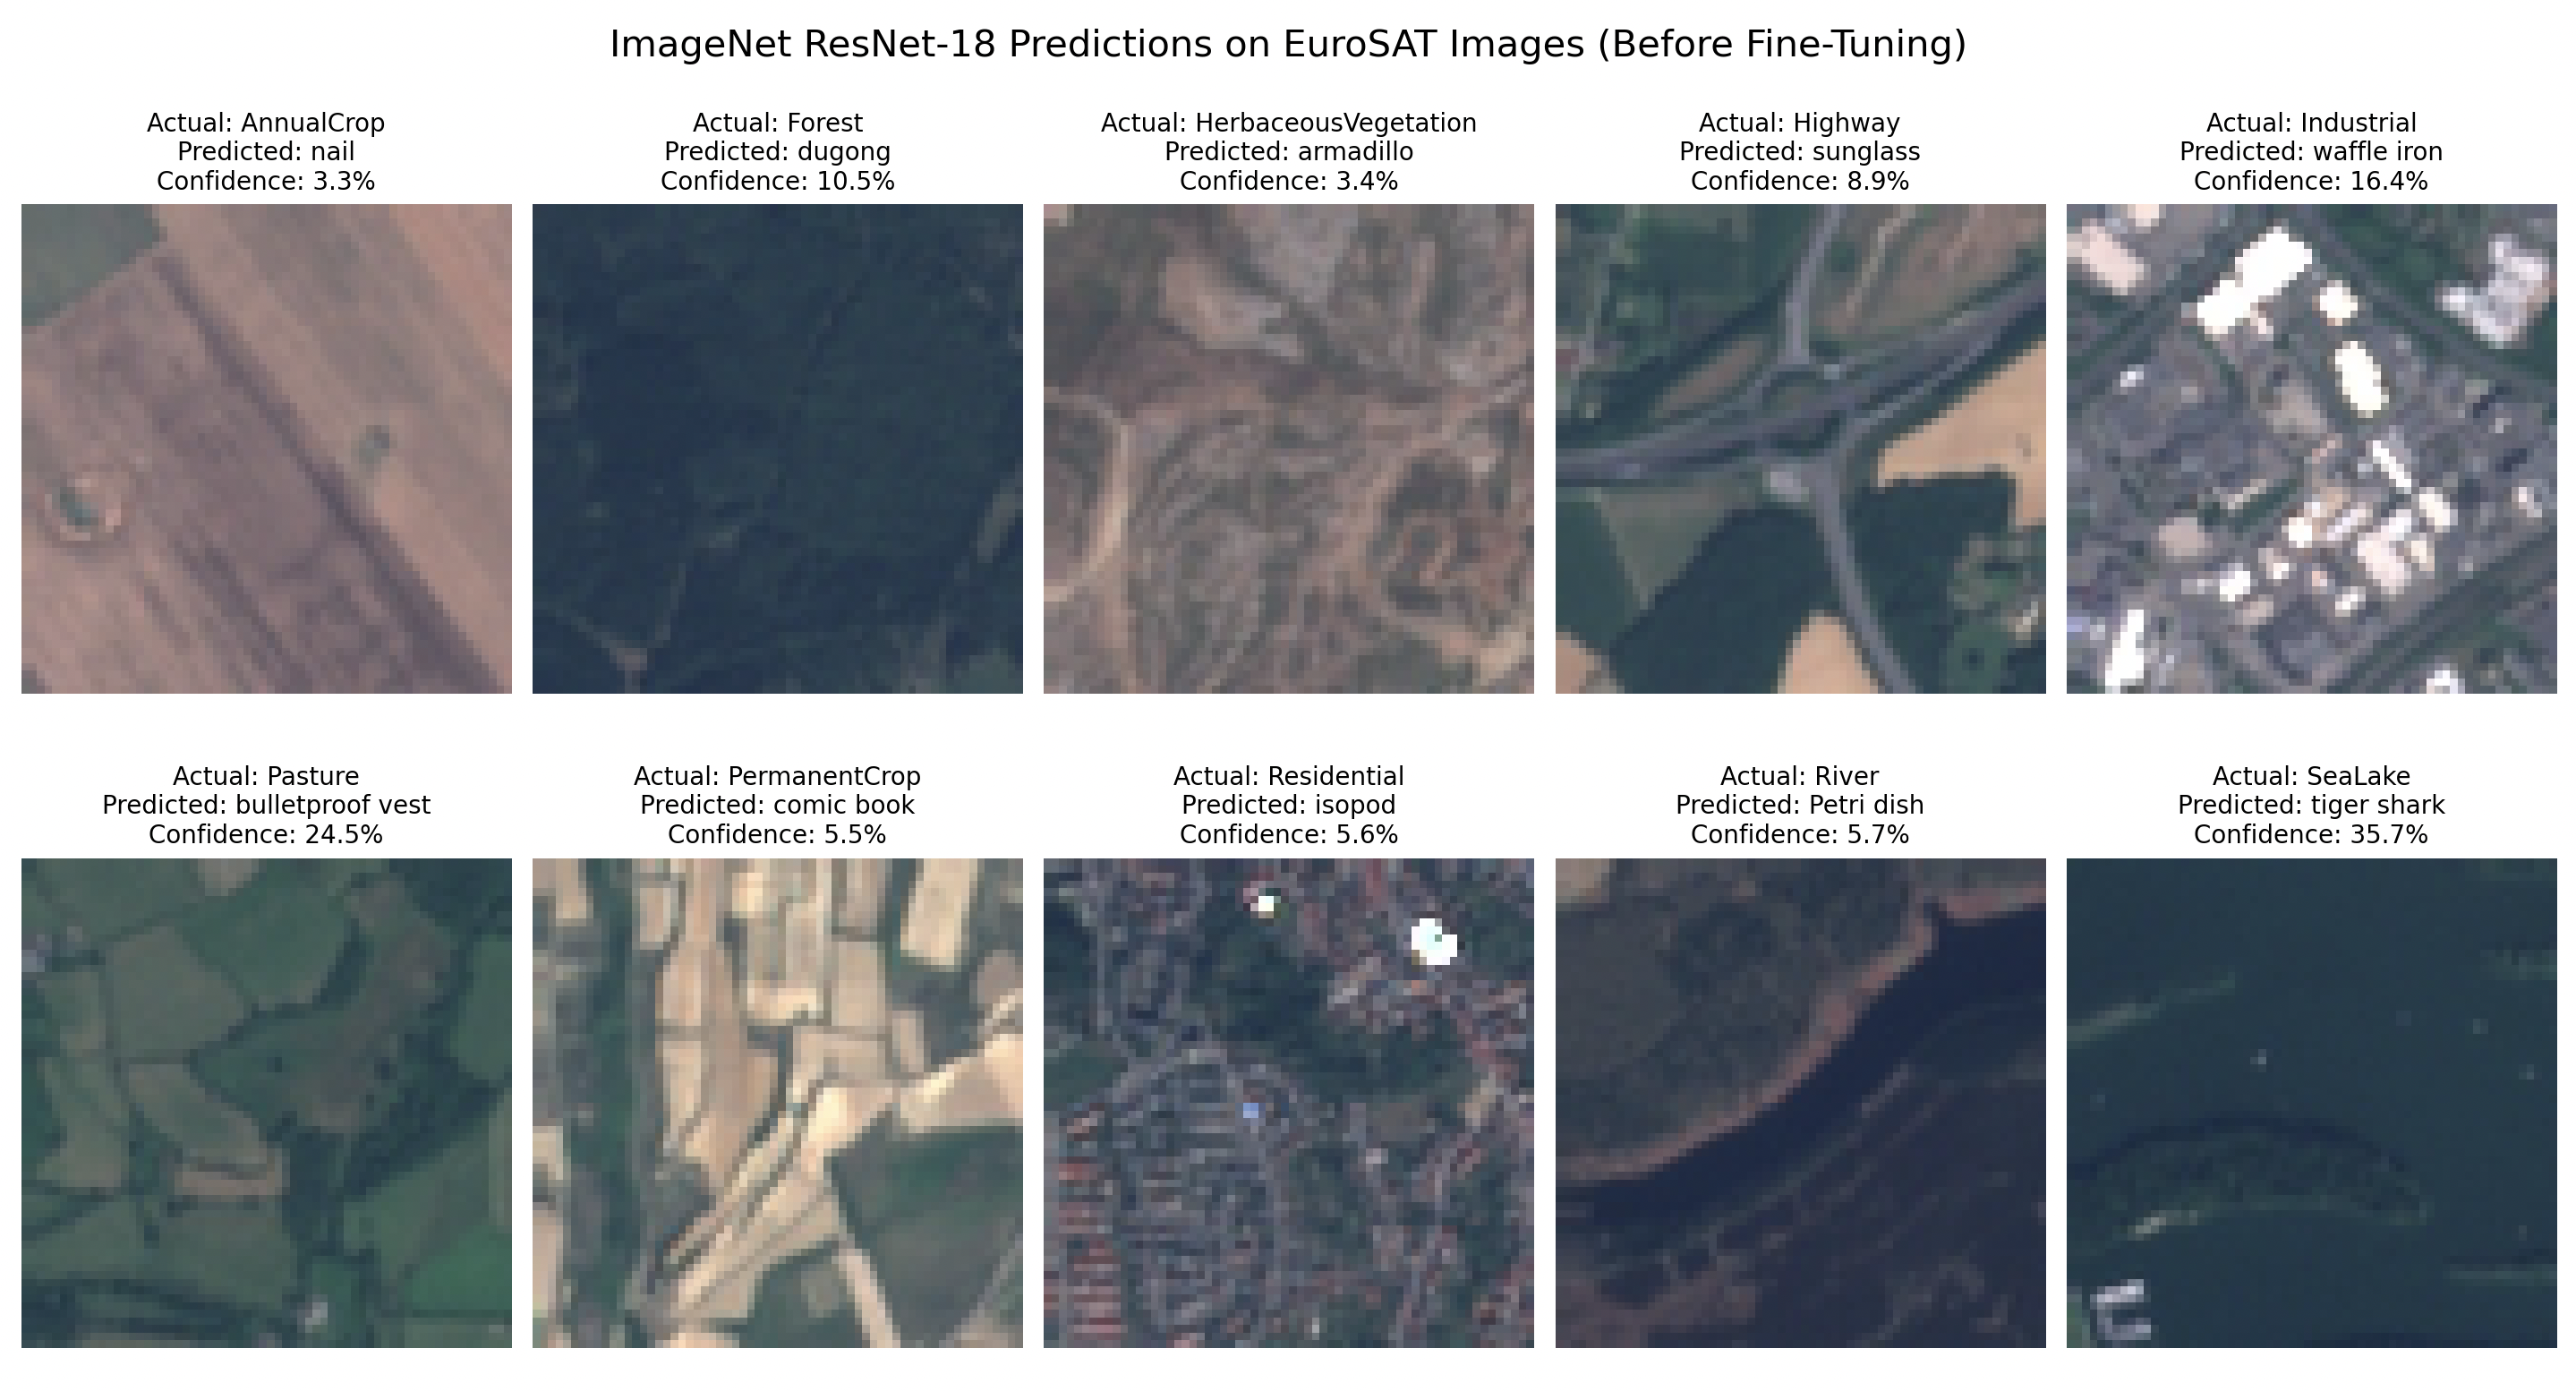

Unsuprisngly, most the images were classified with very low confidence, however there were some exceptions. The sea lake was classified as a tiger shark with 35.7% confidence, whilst the pasture image was classified as a bullet proof vest, with confidence of 24.5%. Although this is not a very representative experiment, it is intresting to see how the model behavues and to understand how it can be mislead.

### Tuning the classification layer

The main part of this analysis will focus on tuning just the final layer. At the moment, the model is trained to classify images into 1000 differnet categories. To tune the model, we must first change the number of categories to 10, whilst keeping the weights in the other layers, fixed. When we begin training the model, only the weights in the final layer will change, although the images will still need to pass through all the previous layers.

In [1]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load original ImageNet-pretrained ResNet-18
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Freeze all pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer
# Original: 512 inputs -> 1000 ImageNet classes
# New:      512 inputs -> 10 EuroSAT classes
model.fc = nn.Linear(model.fc.in_features, 10)

# Keep the pretrained backbone's BatchNorm statistics fixed
model.eval()


# Check number of trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 5130


The fourth residual layer of ResNet18, outputs 512 differnet features. Since we have 10 differnet categories, this results in 5120 differnet parameters extracted, with the addition of 10 bias paremeters per category. As a result, we have a total of 5130 parameters to tune. To get a better understand of the expected run times, i began by training on only 1000 images. I used 1 epoch and a batch size of 32 with the Adam optimiser. Adam combines stochastic gradient decent and momentum, which both effect how fast grdaient decent can locate the minima. I measured the run time and used the result to calculate the time reuqired for the full dataset and larger epochs. 

Training time: 15.12 seconds
Time per image: 0.0151 seconds

Using this run time, we can estimate that a model on the full training set (21,600), with 10 epochs, would take 54 minutes. We will see later whether this estimate was accurate.

Its also importan to considered the differnet hyperparameters in the model. I decided to vary both the learning rate and batch size whilst continuing to train on the reduced dataset of 1000 images. I ran the selection on 2 epochs to gain a little more depth and i considered a mixture of both accuracy as well as cross entropy loss. High cross etropy loss indicates that the model is confident in incorrect predictions, which could be a limitation, even if the model performs well on accracy.

![Screenshot 2026-11-20 at 14.58.37.png](<attachment:Screenshot 2026-11-20 at 14.58.37.png>)
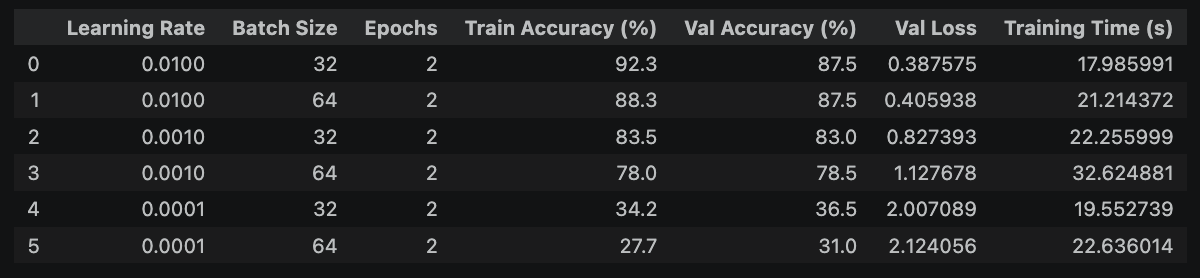

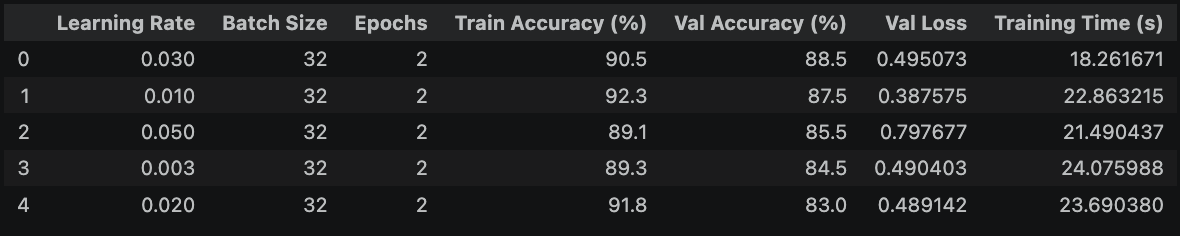

 Smaller batch sized performed better, whilst the learning rate was a little more difficult to narrow down. The 0.03 rate performed best on accuracy, whilst 0.01 had substantually lower loss. I decided to test the learning rate further by considering differnet epoch lengths. 

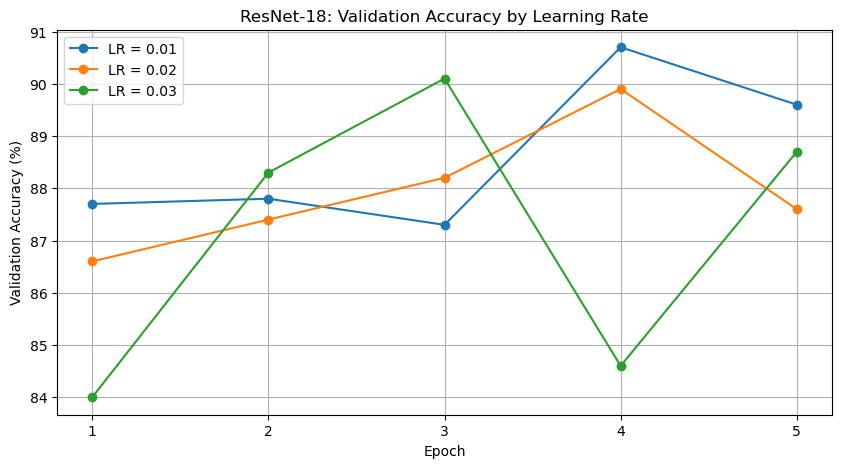

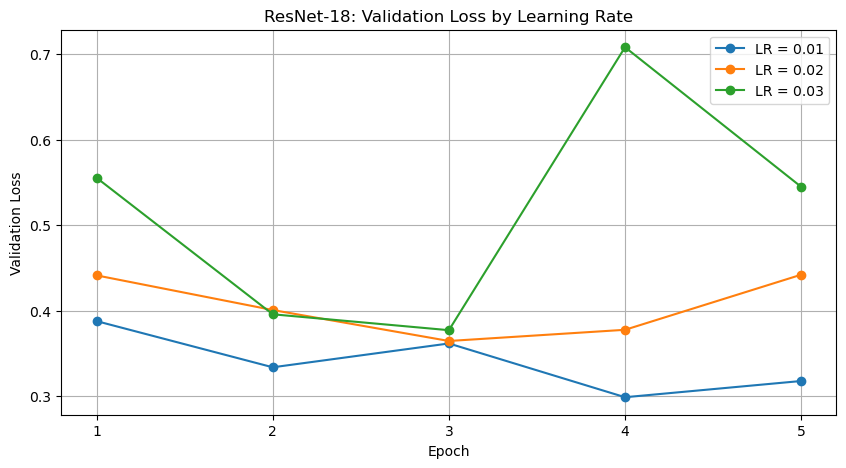

At lower epochs, they performed similairly in both metrics. However, at larger epochs, the learning rate of 0.01 was clearly superior. Therefore, i decided to move foreward with a learning rate of 0.01 alongside a batch size of 32. 

### Model testing on the full dataset

To train the full dataset, I decided to work in five epoch incraments.  The first 5 epochs took 19 minutes to train and resulted in an accuracy of 91.04%. A training time of 19 minute indicates a 10 epoch training time of 38 minutes which is significantly below our previous measured estimate. One explaination could be initial overhead costs for the algorithm. For such a small sample, those costs may dominate and cause an unrepresentative run time. With only one run used to detmerine that estimate, noise and memory availability at the time, may also have been a factor. I proceeded to test 2 more 5 epoch incraments to identify the effect on accuracy and run times. The results illustrated in the figure below.


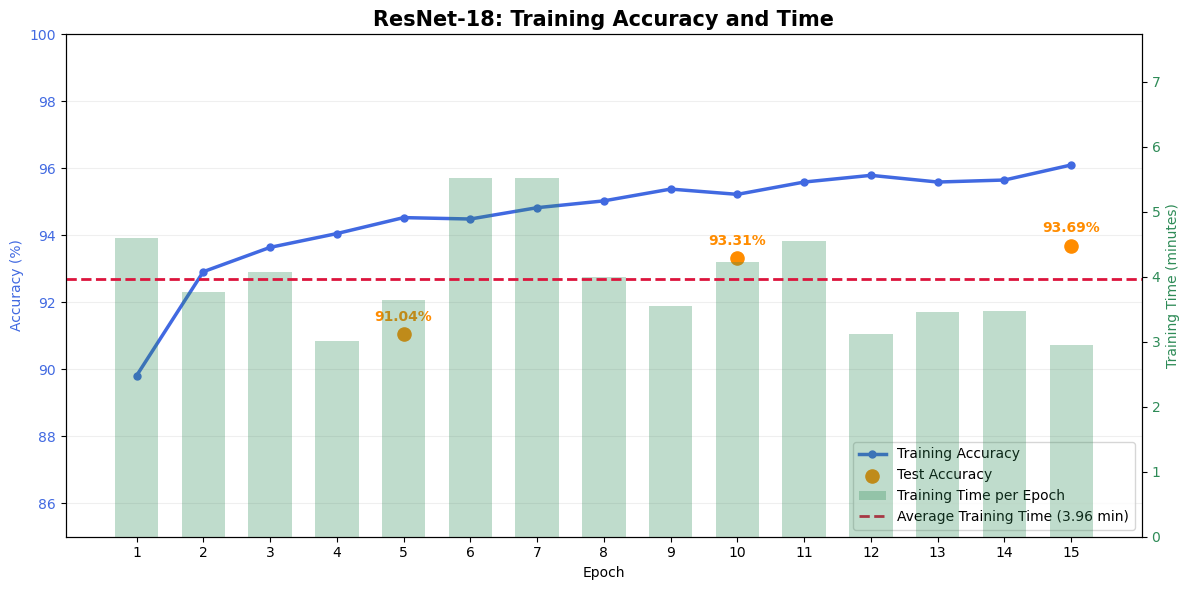

The final testing accuracy was 93.69%. Considering we started with a dataset that was trained on completely different images, an accuracy that high seems quite impressive. However, through transfer learning, the model already knows how to identify many different image features including: edges and boundries - allowing it to pick out roads and fields, textures - used to recognise forests and agriculture, colour patterns - enables seperation between vegetation and water, shapes and spatial structure - differentiates between industrial and residential areas. By adapting and retraining the final layer, we teach it how to apply those patterns to our data-set and retain almost all the benefits of pretraining. Transfer learning is clearly a very useful tool, improving training effciency whilst still achieving high accuracy. 

The plot above is also an excellent example of how much run times can vary, even when each epoch completes the same training process. The average training time was 238 seconds, yet epoch 15 took only 177 whilst epoch 6 took 331. These variation  are most likely a result of background processes, such as Onedrive sychronisation, CPU and GPU utilisation, as well as differencess in image loading. 

Its also useful to consider the the confusion matrix to identify the models category-specfic, strengths and weaknesses.

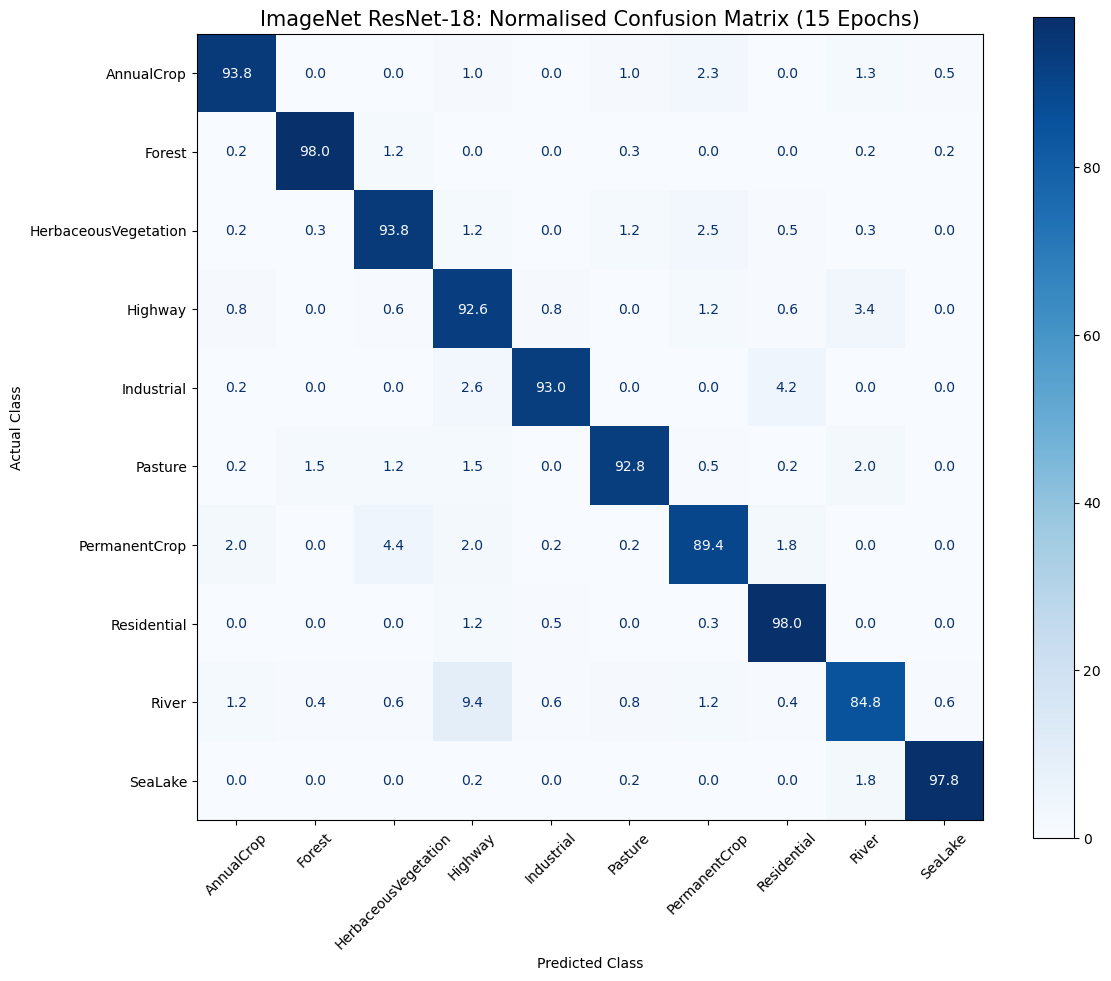

From the figure, a few key values, stand out. The models weakest class, was River, acheving only 84.8% accuracy, compared to the models overall accuracy of 93.69%. The reason for this, is the model mistook river images as highways, 9.4% of the time. Comparing an example from each category below (river left, higher right), the reason for this discrepancy, becomes somewhat clear.

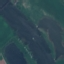 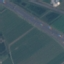

These two examples are very similair in appearance and may be too challenging to differentiate for a partially trained model like ours. The model also struggles to classify PermanentCrop, with a total accuracy of 89.4%. In this case, its down to missclassifying it as HerbaceousVegetation, 4.4% of the time. Once again, we can examine two images from those categories (Permanent crop left, HerbaceousVegetation left):

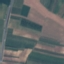. 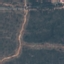

This time the difference is slightly clearer, although the similair tones and field lines could be influencing factors. The only other notable result, would be the missclassification of industrial area, as residential. Those two categories represent the only urban images in the data-set, so that loss in accuracy is somewhat unsuprising. 

### Training additiona layers 

We have already achieved a high accuracy by just training the final layer. As a result, its reasonable to explore how training a further layer, could impact our results. As a I mentioned at the start, ResNet18 is constructed using 6 key blocks, with the previous section focused on tuning the final one. This time, I will unfreeze both the the final classification layer and the fourth residual layer.  Training the 5130 parameters of final layer, didnt pose too much of a computational cost. However, the fourth residual block includes over 8 million trainable parameters. That means we'd need to train 1600 times as many parameters, which if scaled linearly, would render our run time infeasible. The important caveat, is that to train our final layer, the data still had to pass through all the neurons in the previous layers. Hence, the main differnece this time, is the added gradient calculations needed for back propagation. In addition, my macbook uses metal performance shaders, which lets pytorch to utilise GPU processing. This can increase effectivness of parallel learning, increasing speed and efficiency of the algorithm. These factor  combined with the fact that setup and overheads will remain the same, make running this experient, appear more reasonable. In fact, after testing on just one epoch, i released that the difference in costs, was much smaller than anticipated. I tested a few combinations of parametersm  selecting a learning rate of 0.0001 and 0.001 for the fourth block and classification layer respectively. These smaller rates work better here, because they prevent the model learning too aggressively and damaging useful pretrained represnetation. I ended up running on 10 epochs overall, keeping the remaining hyperparameters the same. 

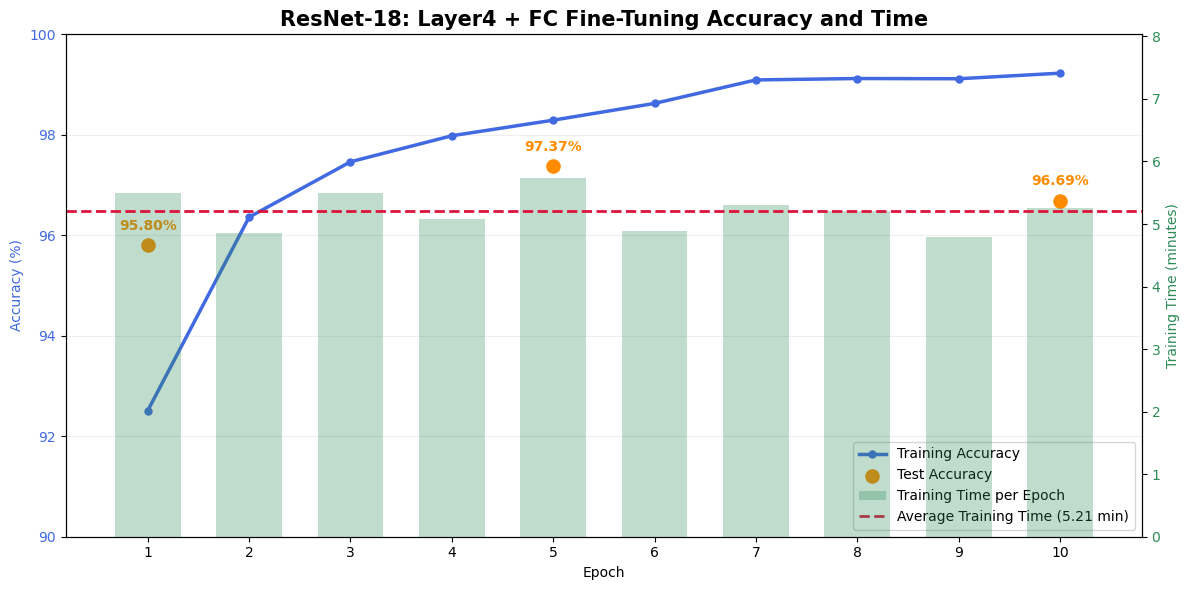

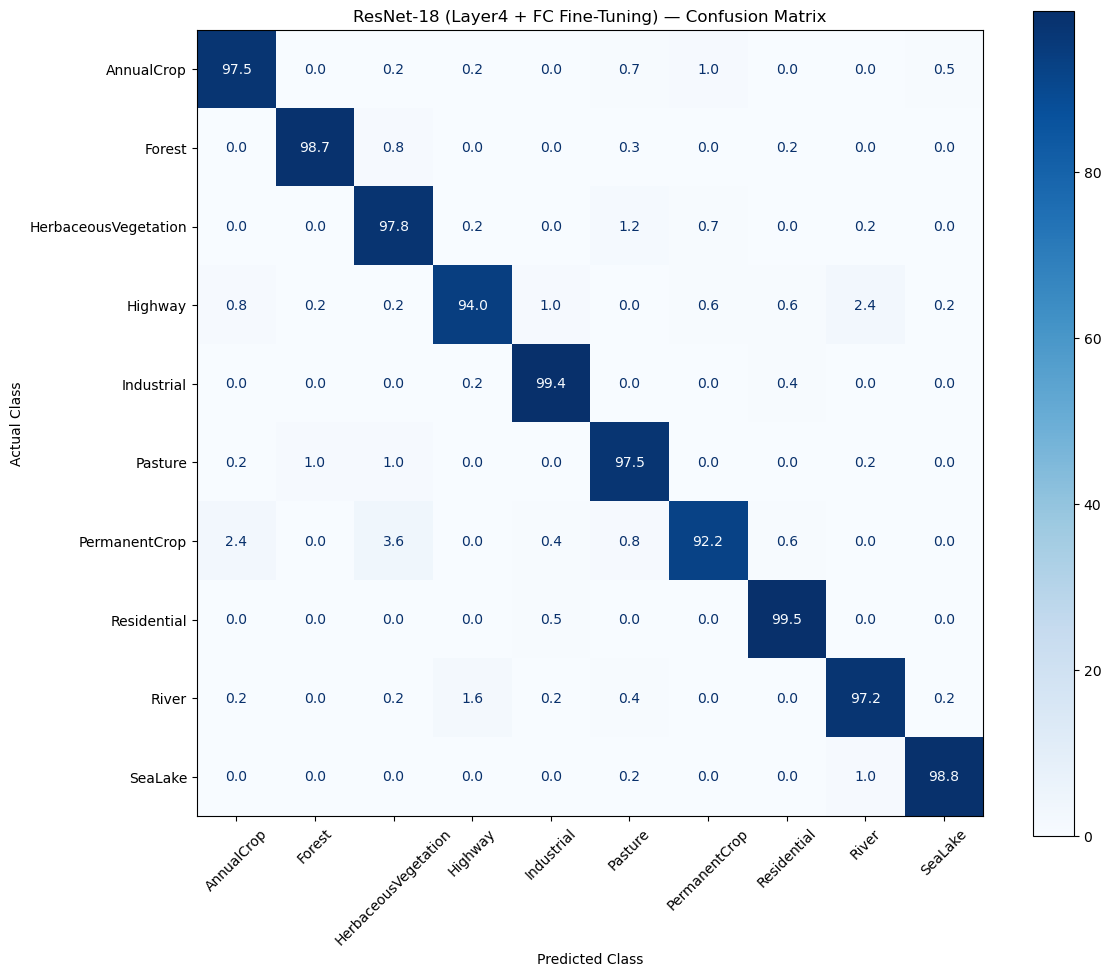

Test accuracy on just one epoch, already surpassed the single layer training model by over 2%. Even more suprisingly, average training time grew to just 313 seconds per epoch. The model achieved a highest test accuracy of 97.37% at epoch 5 and this can partially be attributed to a 12.4% increase in river classification accuracy. Another notable improvement came from the industrila category, which increased accuracy by 6.4%. Training one of the main residual blocks, enabled the model to understand more specfic differneces in our data categories. The main missclassfication still leftover, was PermanentCrop, which may require training of further layers to improve. Training the fourth residual block produced a total improvment, well above what i wasnt expecting and all whilst maintaing a relatively low computational cost. My section was focused on fine tuning, therefore, i didnt explore training further layer. This would be a useuful extension but considering our accuracy already acheived, there exists little scope for imporvovment.